In [1]:
import jax.numpy as jnp
from jax import grad, jit, random
from jax.nn import softmax, relu, one_hot, softplus

import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# seed for pseudo random number generator
key = random.PRNGKey(1)
key1 = random.PRNGKey(3)

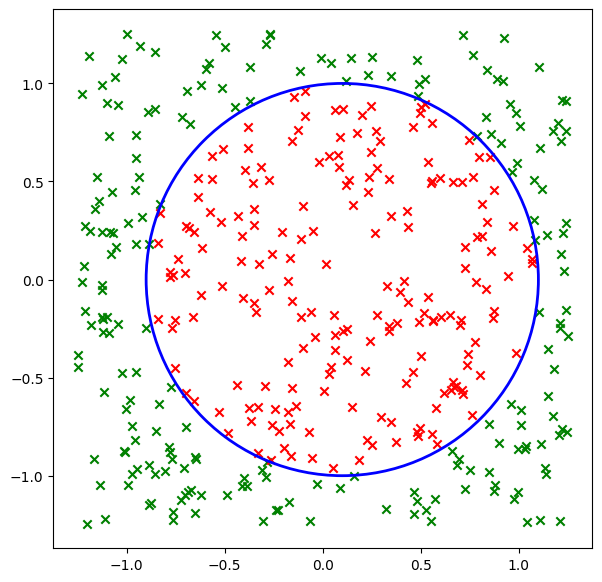

In [2]:
# define a circle and a 
midpoint, radius = (0.1, 0.0), 1
side_length = jnp.sqrt(2*jnp.pi*radius**2)


# generate random points in the square and determine if they lie within the circle
num_samples = 400
x = random.uniform(key, (2, num_samples), minval=-side_length/2, maxval=side_length/2)

classes = (x[0,:] - midpoint[0])**2 + (x[1,:] - midpoint[1])**2 > radius
yhat = one_hot(classes.astype(int), 2).T          


# create a plot of the circle and the samples
fig, ax = plt.subplots(1, figsize=(7, 7))
ax.set_aspect('equal')

ax.scatter(x[0][classes==1], x[1][classes==1], marker= "x", color = "g")
ax.scatter(x[0][classes==0], x[1][classes==0], marker= "x", color = "r")

ax.add_patch(Circle(midpoint, radius, facecolor='None', edgecolor='b', lw=2, zorder=10))

plt.show()

In [3]:
# create network layout

# set number of hidden neurons
num_neurons = [100, 100, 100, 100]

# initialize weight matrizes ramdomly (Xavier initialization)
weight_scaling = lambda n: 1/jnp.sqrt(n)

W = [weight_scaling(indim)*random.normal(key, (outdim, indim)) 
     for outdim, indim in zip(num_neurons + [2], [2] + num_neurons)]

# initialize biases as zero
b = [jnp.zeros(dim) for dim in num_neurons + [2]]

print(f"network hidden layers: {len(num_neurons)}")
print(f"network parameters: {sum(Wk.size for Wk in W) + sum(bk.size for bk in b)}")

network hidden layers: 4
network parameters: 30802


In [4]:
# define the network function
def predict(x, W, b):
    
    z = x  # z^(0) := x
    
    for Wi, bi in zip(W[:-1], b[:-1]):
        
        # z_tilde^(k) = W^(k)z^(k) + b^(k) 
        z_tilde = Wi@z + bi[:, jnp.newaxis]
        
        # z^{k+1} = rho(z_tilde^(k))
        z = relu(z_tilde)
    
    # last layer is special because we use softmax, not relu
    z_tilde = W[-1]@z + b[-1][:,jnp.newaxis]
    
    # softmax for classification
    y = softmax(z_tilde, axis = 0)
    
    return y


print(f"network predicts {x[:, 7]} the classes with probabilities {predict(x, W, b)[:, 7]}")

network predicts [0.8572442 0.740695 ] the classes with probabilities [0.3855147 0.6144853]


In [5]:
# define the loss function
def avg_loss(x, yhat, W,b):
    
    # compute network outputs for input x with given W, b
    y = predict(x,W,b)
    
    # -yhat^T log(y) = -log(yhat^T y) since yhat_i in {0, 1}
    cross_entropy = -jnp.log(jnp.einsum('ij, ij -> j', yhat, y))

    return jnp.average(cross_entropy)


print(f"The initial average loss is {avg_loss(x, yhat, W, b):2f}")

The initial average loss is 0.671323


In [6]:
@jit
def update_step(x,yhat,W, b, step_size = 1e-4):
    # use jax to compute the gradients of avg_loss wrt to the argument with index 2,3, thus W, b
    grads = grad(avg_loss, argnums=[2, 3])(x, yhat, W, b)
  
    # add gradient steps to the weights and return the new weights
    W_new =  [Wi - step_size * dWi for Wi, dWi in zip(W, grads[0])]
    b_new =  [bi - step_size * dbi for bi, dbi in zip(b, grads[1])]
  
    return W_new, b_new

In [7]:
max_iter = 10000

# loop gradient steps
for i in range(max_iter):    
    if i % 1000 == 0:
        print(f"Iteration {i:5} loss {avg_loss(x,yhat,W,b)}")
        
    W, b = update_step(x, yhat, W, b, step_size = 3e-1)

print(f"The average loss after training is {avg_loss(x, yhat, W, b):2f}")

Iteration     0 loss 0.6713225245475769
Iteration  1000 loss 0.00853696558624506
Iteration  2000 loss 0.001081020338460803
Iteration  3000 loss 0.0004294182872399688
Iteration  4000 loss 0.00024356693029403687
Iteration  5000 loss 0.00016190612222999334
Iteration  6000 loss 0.00011869797890540212
Iteration  7000 loss 9.24635969568044e-05
Iteration  8000 loss 7.497861952288076e-05
Iteration  9000 loss 6.25568354735151e-05
The average loss after training is 0.000053


<Figure size 640x480 with 0 Axes>

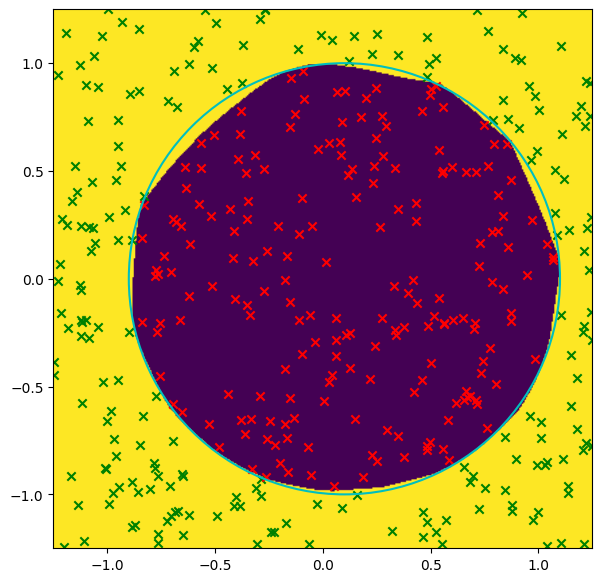

In [8]:
#plot samples and prediction resulting from given W, b in a window around the center point sampleling n^2 points
def plot_prediction(W, b, window_size=1.25, center=(0.0,0.0), n=400):
    plt.clf()
    # some plotting stuff
    fig, ax = plt.subplots(1, figsize=[7,7])
    ax.set_aspect('equal')
    
    # plot scatter
    ax.scatter(x[0][classes==1], x[1][classes==1], marker="x", color="g")
    ax.scatter(x[0][classes==0], x[1][classes==0], marker="x", color="r")
    
    # circle
    circ = Circle(midpoint, radius, facecolor='None', edgecolor='c', lw=1.5, zorder=10)
    ax.add_patch(circ)
    
    # plot prediction
    xs = jnp.linspace(center[0]-window_size, center[0]+window_size, n)
    ys = jnp.linspace(center[1]-window_size, center[1]+window_size, n)
    result = jnp.array([jnp.tile(xs, len(ys)), jnp.repeat(ys, len(xs))])
    A = jnp.flip(predict(result, W,b).argmax(axis = 0).reshape(n,n), axis = 0)
    ax.imshow(A, interpolation='bilinear', extent=[center[0]-window_size,center[0]+window_size,center[1]-window_size,center[1]+window_size])

    plt.show()
    
plot_prediction(W,b)

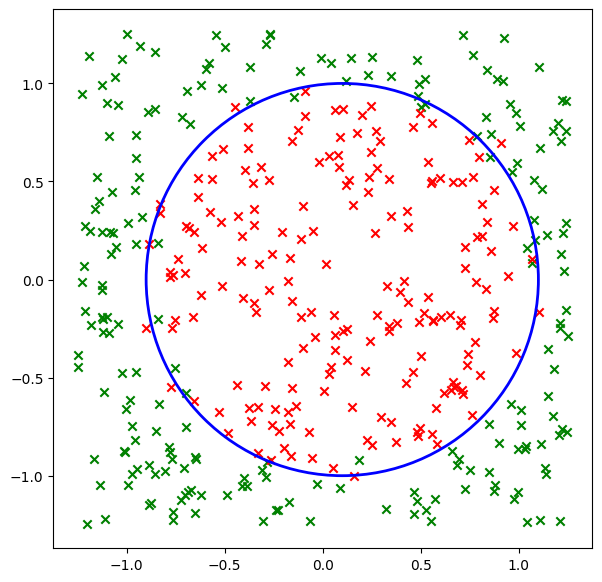

In [9]:
noise = 1e-1*random.uniform(key1,(num_samples,), minval = -1, maxval = 1)
classes = (x[0,:]-midpoint[0])**2 +(x[1,:]-midpoint[1])**2 > (radius + noise)**2 
yhat = one_hot(classes.astype(int), 2).T          


fig,ax = plt.subplots(1, figsize=[7,7])
ax.set_aspect('equal')
# plot scatter
ax.scatter(x[0][classes==1], x[1][classes==1], marker= "x", color = "g")
ax.scatter(x[0][classes==0], x[1][classes==0], marker= "x", color = "r")
# circle
circ = Circle(midpoint, radius, facecolor='None', edgecolor='b', lw=2, zorder=10)
ax.add_patch(circ)
plt.show()

In [10]:
W = [weight_scaling(indim)*random.normal(key,(outdim, indim)) 
     for outdim,indim in zip(num_neurons + [2], [2] + num_neurons)]
b = [jnp.zeros(dim) for dim in num_neurons + [2]]

print(f"The initial average loss is {avg_loss(x, yhat, W, b):2f}")

The initial average loss is 0.667894


iteration     0 loss 0.6678935885429382
iteration  1000 loss 0.08661945909261703
iteration  2000 loss 0.06097591295838356
iteration  3000 loss 0.04351311922073364
iteration  4000 loss 0.020430773496627808
iteration  5000 loss 0.009573368355631828
iteration  6000 loss 0.00586492707952857
iteration  7000 loss 0.004585806746035814
iteration  8000 loss 0.004322370048612356
iteration  9000 loss 0.0039666080847382545
The average loss after training is 0.003749


<Figure size 640x480 with 0 Axes>

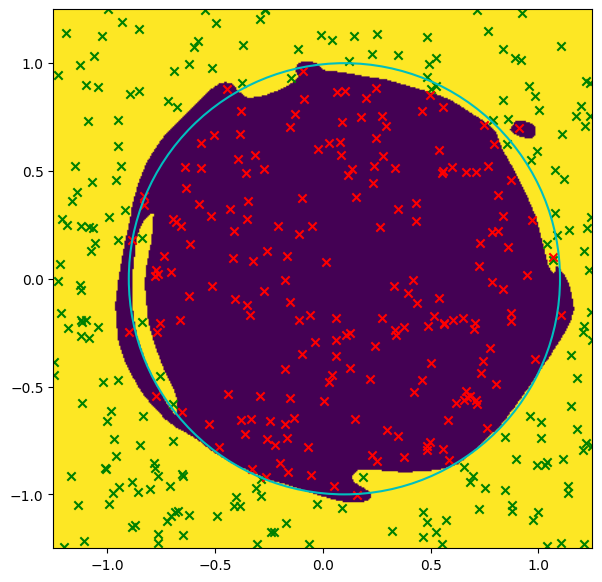

<Figure size 640x480 with 0 Axes>

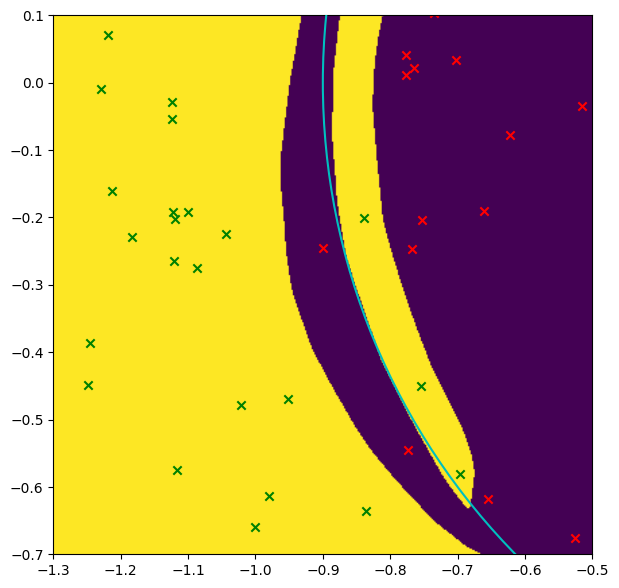

<Figure size 640x480 with 0 Axes>

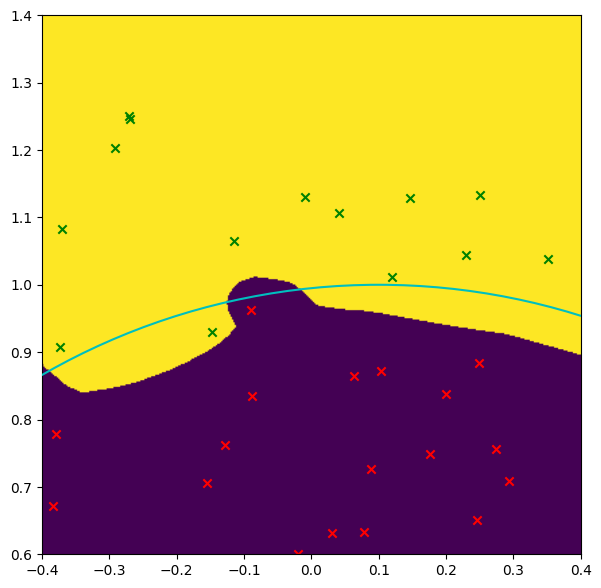

In [11]:
max_iter = 10000

# loop gradient steps
for i in range(max_iter):    
    if i % 1000 == 0:
        print(f"iteration {i:5} loss {avg_loss(x,yhat,W,b)}")
        
    W, b = update_step(x, yhat, W, b, step_size = 3e-1)
    
print(f"The average loss after training is {avg_loss(x, yhat, W, b):2f}")
plot_prediction(W,b)
plot_prediction(W,b, 0.4, (-0.9,-0.3))
plot_prediction(W,b, 0.4, (0,1))
